# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Yan Andhinaya Ardika
- **Email:** ds012b6y1782@student.devacademy.id
- **ID Dicoding:** yanardika

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks:** Dataset berisi ±100 ribu pesanan sebuah marketplace e-commerce Brasil (Olist) pada 2016-2018. Sebagai analis data, tujuan analisis ini adalah membantu tim *marketing*, *operasional*, dan *logistik* menentukan prioritas kategori produk, merencanakan periode puncak penjualan, dan memperbaiki kepuasan pelanggan.

**Cakupan data:** pesanan berstatus `delivered` yang dibeli pada **1 Januari 2017 - 31 Agustus 2018** (2016 dan September-Oktober 2018 dikeluarkan karena jumlah pesanannya sangat sedikit/bulan tidak lengkap). Revenue didefinisikan sebagai jumlah `price` item (belum termasuk ongkos kirim).

- **Pertanyaan 1:** Pada periode Januari 2017 - Agustus 2018, **10 kategori produk mana** yang menyumbang **total revenue** terbesar, dan berapa **rata-rata review score** masing-masing dibandingkan rata-rata keseluruhan (4,08), sehingga tim marketing dapat menentukan kategori prioritas promosi dan kategori yang perlu perbaikan kualitas?
- **Pertanyaan 2:** Bagaimana **tren jumlah pesanan dan total revenue bulanan (Month-over-Month)** selama Januari 2017 - Agustus 2018, **bulan apa** yang mencatat lonjakan tertinggi, dan berapa **pertumbuhan Jan-Agu 2018 dibanding Jan-Agu 2017**, sehingga perusahaan dapat merencanakan stok dan kampanye pada periode puncak?
- **Pertanyaan 3:** Seberapa besar **selisih rata-rata review score** antara pesanan yang tiba tepat waktu dan yang terlambat (dibandingkan tanggal estimasi), serta **di state mana persentase keterlambatan tertinggi**, pada pesanan *delivered* Januari 2017 - Agustus 2018, sehingga tim logistik dapat memprioritaskan perbaikan pengiriman?

| Elemen SMART | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| **Specific** | Kategori produk (top 10) | Pesanan & revenue per bulan | Keterlambatan pengiriman per state |
| **Measurable** | Total revenue (R$), % kontribusi, avg review score | Jumlah pesanan, revenue, % MoM, % YoY | Avg review score, % pesanan terlambat |
| **Action-Oriented** | Prioritas promosi & perbaikan kualitas kategori | Perencanaan stok & kampanye periode puncak | Prioritas perbaikan logistik per wilayah |
| **Relevant** | Sumber pendapatan utama | Pertumbuhan bisnis | Kepuasan & retensi pelanggan |
| **Time-bound** | Jan 2017 - Agu 2018 | Jan 2017 - Agu 2018 | Jan 2017 - Agu 2018 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import folium
import branca.colormap as cm
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)

## Data Wrangling

### Gathering Data

#### Load data transaksi (orders, order items, payments, reviews)

In [2]:
!unzip -qo E-commerce-public-dataset.zip

In [3]:
DATA_DIR = "E-Commerce Public Dataset"

orders_df = pd.read_csv(f"{DATA_DIR}/orders_dataset.csv")
order_items_df = pd.read_csv(f"{DATA_DIR}/order_items_dataset.csv")
order_payments_df = pd.read_csv(f"{DATA_DIR}/order_payments_dataset.csv")
order_reviews_df = pd.read_csv(f"{DATA_DIR}/order_reviews_dataset.csv")

for name, df in {"orders_df": orders_df, "order_items_df": order_items_df,
                 "order_payments_df": order_payments_df, "order_reviews_df": order_reviews_df}.items():
    print(f"{name:<20} {df.shape[0]:>8,} baris | {df.shape[1]} kolom")
orders_df.head()

orders_df              99,441 baris | 8 kolom
order_items_df        112,650 baris | 7 kolom
order_payments_df     103,886 baris | 5 kolom
order_reviews_df       99,224 baris | 7 kolom


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load data master (customers, sellers, products, translation, geolocation)

In [4]:
customers_df = pd.read_csv(f"{DATA_DIR}/customers_dataset.csv")
sellers_df = pd.read_csv(f"{DATA_DIR}/sellers_dataset.csv")
products_df = pd.read_csv(f"{DATA_DIR}/products_dataset.csv")
translation_df = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")
geolocation_df = pd.read_csv(f"{DATA_DIR}/geolocation_dataset.csv")

for name, df in {"customers_df": customers_df, "sellers_df": sellers_df, "products_df": products_df,
                 "translation_df": translation_df, "geolocation_df": geolocation_df}.items():
    print(f"{name:<20} {df.shape[0]:>9,} baris | {df.shape[1]} kolom")
display(products_df.head())
customers_df.head()

customers_df            99,441 baris | 5 kolom
sellers_df               3,095 baris | 4 kolom
products_df             32,951 baris | 9 kolom
translation_df              71 baris | 2 kolom
geolocation_df       1,000,163 baris | 5 kolom


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


**Insight:**
- Dataset terdiri dari **9 tabel** yang saling berelasi dimana tabel `orders` terhubung ke tabel `customers` (`customer_id`), `order_items` (`order_id`), dan `order_reviews` (`order_id`). Tabel `order_items` terhubung ke tabel `products` (`product_id`) dan tabel `sellers` (`seller_id`). Kategori produk Portugis diterjemahkan lewat tabel `product_category_name_translation`.
- Satu pelanggan fisik dapat memiliki beberapa `customer_id` dan identitas pelanggan yang sebenarnya ada pada `customer_unique_id`.
- Tabel `order_payments` dan `sellers` dimuat untuk kelengkapan *assessing*, tetapi tidak dipakai pada analisis. Tabel `geolocation` dipakai pada analisis geospasial untuk menentukan titik koordinat tiap state.

### Assessing Data

#### Identifying data type problem (invalid data type)

In [5]:
orders_df.info()
print()
print(order_items_df[["shipping_limit_date"]].dtypes)
print()
print(order_reviews_df[["review_creation_date", "review_answer_timestamp"]].dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

shipping_limit_date    object
dtype: object

review_creation_date       object
review_answer_timestamp    object
dtype: object


**Steps to Take:**
- Kolom tanggal/waktu (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`, `shipping_limit_date`, `review_creation_date`, `review_answer_timestamp`) masih bertipe teks, sehingga tidak bisa dihitung selisihnya.
- Konversi seluruh kolom tersebut ke `datetime` pada tahap *cleaning*.

#### Identifying missing value problem

In [6]:
all_tables = {
    "orders_df": orders_df, "order_items_df": order_items_df, "order_payments_df": order_payments_df,
    "order_reviews_df": order_reviews_df, "customers_df": customers_df, "sellers_df": sellers_df,
    "products_df": products_df, "translation_df": translation_df, "geolocation_df": geolocation_df,
}

missing_rows = []
for name, df in all_tables.items():
    for col, n in df.isna().sum().items():
        if n > 0:
            missing_rows.append({"tabel": name, "kolom": col, "jumlah_missing": n,
                                 "persentase_missing": n / len(df) * 100})
missing_summary = pd.DataFrame(missing_rows)
display(missing_summary)

# Apakah missing value pada orders_df wajar (sesuai status pesanan)?
print("Jumlah order_delivered_customer_date kosong berdasarkan order_status:")
print(orders_df[orders_df["order_delivered_customer_date"].isna()]["order_status"].value_counts())
print()
print("Produk tanpa nama kategori:", products_df["product_category_name"].isna().sum())

,tabel,kolom,jumlah_missing,persentase_missing
0,orders_df,order_approved_at,160,0.16
1,orders_df,order_delivered_carrier_date,1783,1.79
2,orders_df,order_delivered_customer_date,2965,2.98
3,order_reviews_df,review_comment_title,87656,88.34
4,order_reviews_df,review_comment_message,58247,58.70
5,products_df,product_category_name,610,1.85
6,products_df,product_name_lenght,610,1.85
7,products_df,product_description_lenght,610,1.85
8,products_df,product_photos_qty,610,1.85
9,products_df,product_weight_g,2,0.01


Jumlah order_delivered_customer_date kosong berdasarkan order_status:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

Produk tanpa nama kategori: 610


**Steps to Take:**
- `order_delivered_customer_date` kosong pada 2.965 pesanan, hampir seluruhnya wajar karena status pesanan belum `delivered` (shipped, canceled, dsb.), tetapi **8 pesanan berstatus `delivered` tanpa tanggal tiba** -> dibuang karena keterlambatannya tidak dapat dihitung.
- `product_category_name` kosong pada 610 produk (1,85%) -> isi dengan label `"unknown"` agar item penjualannya tetap terhitung.
- `review_comment_title` (88%) dan `review_comment_message` (59%) banyak kosong karena komentar bersifat opsional, kolom tidak dipakai sehingga dibiarkan.

#### Identifying duplicate data problem

In [7]:
dup_summary = pd.DataFrame({
    "tabel": list(all_tables.keys()),
    "baris_duplikat": [df.duplicated().sum() for df in all_tables.values()],
    "jumlah_baris": [len(df) for df in all_tables.values()],
})
display(dup_summary)

# Duplikasi: satu order seharusnya memiliki satu ulasan
print("Jumlah order_id yang muncul lebih dari sekali di order_reviews_df:",
      order_reviews_df["order_id"].duplicated().sum())
print("Jumlah order_id duplikat di orders_df:", orders_df["order_id"].duplicated().sum())

,tabel,baris_duplikat,jumlah_baris
0,orders_df,0,99441
1,order_items_df,0,112650
2,order_payments_df,0,103886
3,order_reviews_df,0,99224
4,customers_df,0,99441
5,sellers_df,0,3095
6,products_df,0,32951
7,translation_df,0,71
8,geolocation_df,261831,1000163


Jumlah order_id yang muncul lebih dari sekali di order_reviews_df: 551
Jumlah order_id duplikat di orders_df: 0


**Steps to Take:**
- `geolocation_df` memiliki **261.831 baris duplikat** (26% data) -> hapus dengan `drop_duplicates()`.
- **551 `order_id` memiliki lebih dari satu ulasan** di `order_reviews_df`. Jika langsung digabung ke `orders_df`, satu pesanan akan terhitung ganda dan revenue ikut menggelembung -> simpan hanya ulasan terakhir per pesanan.

#### Identifying inconsistent / inaccurate value problem

In [8]:
tmp = orders_df.copy()
for col in ["order_purchase_timestamp", "order_delivered_carrier_date", "order_delivered_customer_date"]:
    tmp[col] = pd.to_datetime(tmp[col])

delivered_tmp = tmp[tmp["order_status"] == "delivered"]

print("Distribusi order_status:")
print(tmp["order_status"].value_counts())
print()
print("Pesanan 'delivered' tetapi tanpa tanggal tiba di pelanggan :",
      delivered_tmp["order_delivered_customer_date"].isna().sum())
print("Pesanan non-delivered tetapi memiliki tanggal tiba         :",
      tmp[(tmp["order_status"] != "delivered") & tmp["order_delivered_customer_date"].notna()].shape[0])
print("Pesanan 'delivered' dengan tanggal kirim ke kurir > tanggal tiba di pelanggan :",
      (delivered_tmp["order_delivered_carrier_date"] > delivered_tmp["order_delivered_customer_date"]).sum())
print("Pesanan 'delivered' dengan tanggal tiba < tanggal pembelian :",
      (delivered_tmp["order_delivered_customer_date"] < delivered_tmp["order_purchase_timestamp"]).sum())
print()

# Kategori produk berbahasa Portugis yang tidak punya terjemahan
untranslated = set(products_df["product_category_name"].dropna()) - set(translation_df["product_category_name"])
print("Kategori produk tanpa terjemahan Inggris:", untranslated)

Distribusi order_status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Pesanan 'delivered' tetapi tanpa tanggal tiba di pelanggan : 8
Pesanan non-delivered tetapi memiliki tanggal tiba         : 6
Pesanan 'delivered' dengan tanggal kirim ke kurir > tanggal tiba di pelanggan : 23
Pesanan 'delivered' dengan tanggal tiba < tanggal pembelian : 0

Kategori produk tanpa terjemahan Inggris: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


**Steps to Take:**
- **23 pesanan `delivered`** memiliki tanggal serah ke kurir yang **lebih akhir** dari tanggal tiba di pelanggan (urutan waktu mustahil) -> dibuang.
- 6 pesanan berstatus `canceled` memiliki tanggal tiba sehingga tidak perlu diperbaiki karena analisis hanya memakai pesanan `delivered`.
- Dua kategori produk (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`) tidak ada di tabel terjemahan -> tambahkan terjemahannya secara manual agar nama kategori konsisten (Inggris).

#### Identifying outlier problem

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

display(order_items_df[["price", "freight_value"]].describe())
for col in ["price", "freight_value"]:
    n = iqr_outliers(order_items_df[col])
    print(f"Outlier (metode IQR) pada {col:<14}: {n:,} baris ({n / len(order_items_df):.1%})")

print()
print("5 harga tertinggi:", order_items_df["price"].nlargest(5).tolist())

,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68


Outlier (metode IQR) pada price         : 8,427 baris (7.5%)
Outlier (metode IQR) pada freight_value : 12,134 baris (10.8%)

5 harga tertinggi: [6735.0, 6729.0, 6499.0, 4799.0, 4690.0]


**Steps to Take:**
- Terdapat 7,5% item dengan harga *outlier* (max 6.735 BRL, sedangkan median hanya 74,99 BRL) dan 10,8% dengan ongkir *outlier*.
- Nilai tersebut masuk akal (barang mahal / pengiriman jauh), sehingga **tidak dihapus**, cukup dicatat bahwa rata-rata harga dipengaruhi outlier dan perbandingan kategori memakai total revenue serta jumlah unit.

**Insight:**
- Masalah kualitas data yang ditemukan: **tipe data tidak sesuai, missing value, data duplikat, nilai tidak konsisten/tidak akurat, dan outlier** (5 jenis, syarat minimal adalah 2).
- Sebagian besar masalah bersifat ringan dan terisolasi (< 2% data) kecuali duplikasi `geolocation` dan duplikasi ulasan pada kolom `order_id`.

### Cleaning Data

#### Fixing data type problem

In [10]:
for col in ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])
for col in ["review_creation_date", "review_answer_timestamp"]:
    order_reviews_df[col] = pd.to_datetime(order_reviews_df[col])

orders_df.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


#### Fixing missing value problem

In [11]:
# 1) Produk tanpa kategori -> diberi label "unknown" agar tidak hilang saat merge
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
print("Produk tanpa kategori setelah dibersihkan:", products_df["product_category_name"].isna().sum())

# 2) Pesanan 'delivered' tanpa tanggal tiba -> dibuang karena tidak bisa dihitung keterlambatannya
n_before = len(orders_df)
mask_no_date = (orders_df["order_status"] == "delivered") & orders_df["order_delivered_customer_date"].isna()
orders_df = orders_df[~mask_no_date].copy()
print(f"Baris dibuang (delivered tanpa tanggal tiba): {n_before - len(orders_df)}")

# 3) Missing value pada order_status selain delivered (shipped, canceled, dsb.) adalah wajar
# dan tidak perlu diisi karena pesanan tersebut tidak dipakai pada analisis.

Produk tanpa kategori setelah dibersihkan: 0
Baris dibuang (delivered tanpa tanggal tiba): 8


#### Fixing duplicate data problem

In [12]:
# 1) Satu order memiliki lebih dari satu ulasan -> ambil ulasan paling akhir
n_before = len(order_reviews_df)
order_reviews_df = (order_reviews_df
                    .sort_values("review_answer_timestamp")
                    .drop_duplicates(subset="order_id", keep="last"))
print(f"order_reviews_df: {n_before:,} -> {len(order_reviews_df):,} baris | order_id duplikat: {order_reviews_df['order_id'].duplicated().sum()}")

# 2) Baris duplikat pada geolocation_df
n_before = len(geolocation_df)
geolocation_df = geolocation_df.drop_duplicates()
print(f"geolocation_df  : {n_before:,} -> {len(geolocation_df):,} baris | baris duplikat: {geolocation_df.duplicated().sum()}")

order_reviews_df: 99,224 -> 98,673 baris | order_id duplikat: 0
geolocation_df  : 1,000,163 -> 738,332 baris | baris duplikat: 0


#### Fixing inconsistent / inaccurate value problem

In [13]:
# 1) Tanggal kirim ke kurir > tanggal tiba di pelanggan (secara logika mustahil) -> dibuang
mask_invalid = (orders_df["order_status"] == "delivered") & \
               (orders_df["order_delivered_carrier_date"] > orders_df["order_delivered_customer_date"])
print("Baris dengan urutan tanggal tidak logis:", mask_invalid.sum())
orders_df = orders_df[~mask_invalid].copy()

# 2) Tambahkan terjemahan untuk kategori yang belum tersedia lalu gabungkan ke products_df
extra_translation = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos", "unknown"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers", "unknown"],
})
translation_df = pd.concat([translation_df, extra_translation], ignore_index=True)
products_df = products_df.merge(translation_df, on="product_category_name", how="left")

print("Kategori tanpa terjemahan setelah dibersihkan:", products_df["product_category_name_english"].isna().sum())
print("Jumlah kategori unik:", products_df["product_category_name_english"].nunique())

Baris dengan urutan tanggal tidak logis: 23
Kategori tanpa terjemahan setelah dibersihkan: 0
Jumlah kategori unik: 74


#### Handling outlier problem

In [14]:
# Outlier harga/ongkir tidak dibuang: nilainya valid (mis. produk elektronik/perabot mahal) dan
# merupakan bagian dari revenue yang sebenarnya. Dampaknya dikendalikan dengan membandingkan
# mean dan median serta menggunakan total revenue (bukan hanya rata-rata) pada analisis.
q1, q3 = order_items_df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
share = order_items_df.loc[order_items_df["price"] > upper, "price"].sum() / order_items_df["price"].sum()
print(f"Batas atas outlier harga (IQR): R$ {upper:,.2f}")
print(f"Kontribusi item outlier terhadap total nilai penjualan: {share:.1%}")
print(f"Mean harga: R$ {order_items_df['price'].mean():,.2f} | Median harga: R$ {order_items_df['price'].median():,.2f}")

Batas atas outlier harga (IQR): R$ 277.40
Kontribusi item outlier terhadap total nilai penjualan: 35.6%
Mean harga: R$ 120.65 | Median harga: R$ 74.99


#### Menyiapkan dataset untuk analisis (filter periode & merge tabel)

In [15]:
# Cakupan analisis: pesanan berstatus delivered, dibeli 1 Jan 2017 - 31 Agu 2018
# (2016 dan Sep-Okt 2018 dikeluarkan karena datanya sangat sedikit / bulan tidak lengkap)
START, END = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-09-01")

delivered_df = orders_df[
    (orders_df["order_status"] == "delivered")
    & (orders_df["order_purchase_timestamp"] >= START)
    & (orders_df["order_purchase_timestamp"] < END)
].copy()

# Tabel level pesanan (1 baris = 1 order)
order_revenue = (order_items_df.groupby("order_id")
                 .agg(revenue=("price", "sum"), freight=("freight_value", "sum"), total_items=("order_item_id", "count"))
                 .reset_index())

order_df = (delivered_df
            .merge(customers_df[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
            .merge(order_reviews_df[["order_id", "review_score"]], on="order_id", how="left")
            .merge(order_revenue, on="order_id", how="left"))

print("Delivered order tanpa item (revenue kosong):", order_df["revenue"].isna().sum())
order_df = order_df.dropna(subset=["revenue"]).copy()
print("Delivered order tanpa review                :", order_df["review_score"].isna().sum())

# Tabel level item (1 baris = 1 item terjual) untuk analisis kategori
item_df = (order_items_df
           .merge(order_df[["order_id", "order_purchase_timestamp", "review_score"]], on="order_id", how="inner")
           .merge(products_df[["product_id", "product_category_name_english"]], on="product_id", how="left"))

print()
print(f"order_df : {order_df.shape[0]:,} pesanan | {order_df['order_purchase_timestamp'].min():%d %b %Y} - {order_df['order_purchase_timestamp'].max():%d %b %Y}")
print(f"item_df  : {item_df.shape[0]:,} item")
order_df.head()

Delivered order tanpa item (revenue kosong): 0
Delivered order tanpa review                : 643

order_df : 96,184 pesanan | 05 Jan 2017 - 29 Aug 2018
item_df  : 109,827 item


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,review_score,revenue,freight,total_items
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,SP,4.00,29.99,8.72,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,BA,4.00,118.70,22.76,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,GO,5.00,159.90,19.22,1
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,RN,5.00,45.00,27.20,1
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,SP,5.00,19.90,8.72,1


**Insight:**
- Setelah pembersihan dan penyaringan, analisis memakai **96.184 pesanan** (`order_df`, level pesanan) dan **109.827 item** (`item_df`, level item).
- 643 pesanan belum memiliki ulasan, pesanan tersebut tetap dihitung untuk revenue dan pengiriman, tetapi otomatis tidak ikut dalam rata-rata review score.
- Karena `revenue` dihitung dari `price` saja, ongkos kirim tidak ikut menggelembungkan pendapatan kategori.

## Exploratory Data Analysis (EDA)

### Explore kategori produk: revenue, volume, dan review score (Pertanyaan 1)

In [16]:
category_summary = (item_df.groupby("product_category_name_english")
                   .agg(total_revenue=("price", "sum"),
                        total_orders=("order_id", "nunique"),
                        units_sold=("order_item_id", "count"),
                        avg_price=("price", "mean"),
                        avg_review_score=("review_score", "mean"))
                   .sort_values("total_revenue", ascending=False))
category_summary["revenue_share_pct"] = category_summary["total_revenue"] / category_summary["total_revenue"].sum() * 100
category_summary["cumulative_share_pct"] = category_summary["revenue_share_pct"].cumsum()

print("Total revenue (Jan 2017 - Agu 2018): R$ {:,.2f}".format(category_summary["total_revenue"].sum()))
print("Jumlah kategori:", len(category_summary))
print()
print("10 kategori dengan revenue tertinggi:")
display(category_summary.head(10))
print("5 kategori dengan revenue terendah:")
category_summary.tail(5)

Total revenue (Jan 2017 - Agu 2018): R$ 13,176,606.15
Jumlah kategori: 74

10 kategori dengan revenue tertinggi:


,total_revenue,total_orders,units_sold,avg_price,avg_review_score,revenue_share_pct,cumulative_share_pct
product_category_name_english,,,,,,,
health_beauty,"1,229,425.70",8608,9420,130.51,4.19,9.33,9.33
watches_gifts,"1,163,121.02",5488,5852,198.76,4.07,8.83,18.16
bed_bath_table,"1,022,541.17",9264,10941,93.46,3.92,7.76,25.92
sports_leisure,"952,476.41",7510,8411,113.24,4.17,7.23,33.15
computers_accessories,"887,761.73",6515,7629,116.37,3.99,6.74,39.88
furniture_decor,"705,756.22",6252,8086,87.28,3.96,5.36,45.24
housewares,"614,143.12",5731,6774,90.66,4.11,4.66,49.90
cool_stuff,"609,070.01",3551,3710,164.17,4.20,4.62,54.52
auto,"577,695.10",3800,4130,139.88,4.12,4.38,58.91


5 kategori dengan revenue terendah:


,total_revenue,total_orders,units_sold,avg_price,avg_review_score,revenue_share_pct,cumulative_share_pct
product_category_name_english,,,,,,,
flowers,"1,110.04",29,33,33.64,4.42,0.01,99.98
home_comfort_2,760.27,24,30,25.34,3.63,0.01,99.99
cds_dvds_musicals,730.00,12,14,52.14,4.64,0.01,99.99
fashion_childrens_clothes,519.95,7,7,74.28,5.00,0.00,100.00
security_and_services,283.29,2,2,141.64,2.50,0.00,100.00


In [17]:
top10 = category_summary.head(10)
print(f"Kontribusi 10 kategori teratas terhadap total revenue: {top10['revenue_share_pct'].sum():.1f}%")
print(f"Rata-rata review seluruh item                        : {item_df['review_score'].mean():.2f}")
print()
print("Kategori (min. 500 item terjual) dengan review score terendah:")
(category_summary[category_summary["units_sold"] >= 500]
 .sort_values("avg_review_score")[["units_sold", "total_revenue", "avg_review_score"]].head(5))

Kontribusi 10 kategori teratas terhadap total revenue: 62.5%
Rata-rata review seluruh item                        : 4.08

Kategori (min. 500 item terjual) dengan review score terendah:


,units_sold,total_revenue,avg_review_score
product_category_name_english,,,
office_furniture,1661,"266,683.49",3.52
bed_bath_table,10941,"1,022,541.17",3.92
unknown,1534,"170,600.84",3.94
furniture_decor,8086,"705,756.22",3.96
home_construction,596,"81,407.57",3.96


**Insight:**
- Total revenue periode analisis **13,18 juta BRL** dari 74 kategori. **10 kategori teratas menyumbang 62,5%** revenue, jadi pendapatan cukup terkonsentrasi.
- Peringkat teratas: `health_beauty` (1,23 juta BRL (9,3%)), `watches_gifts` (1,16 juta BRL (8,8%)), `bed_bath_table` (1,02 juta BRL (7,8%)), `sports_leisure` (0,95 juta BRL) dan `computers_accessories` (0,89 juta BRL).
- `bed_bath_table` memiliki unit terjual terbanyak (10.941) tetapi harga rata-rata rendah (93 BRL), sedangkan `watches_gifts` bernilai rata-rata tertinggi (199 BRL) dengan unit jauh lebih sedikit (5.852).
- Review score `watches_gifts` (4,07), `bed_bath_table` (3,92), `computers_accessories` (3,99), dan `furniture_decor` (3,96) berada di bawah rata-rata keseluruhan (4,08). Di luar 10 besar, `office_furniture` terendah (3,52) pada kategori dengan >= 500 item.

### Explore tren pesanan dan revenue bulanan (Pertanyaan 2)

In [18]:
order_df["order_month"] = order_df["order_purchase_timestamp"].dt.to_period("M")

monthly = (order_df.groupby("order_month")
           .agg(total_orders=("order_id", "nunique"),
                total_revenue=("revenue", "sum"),
                avg_order_value=("revenue", "mean")))
monthly["orders_mom_pct"] = monthly["total_orders"].pct_change() * 100
monthly["revenue_mom_pct"] = monthly["total_revenue"].pct_change() * 100
monthly

,total_orders,total_revenue,avg_order_value,orders_mom_pct,revenue_mom_pct
order_month,,,,,
2017-01,749,"111,609.71",149.01,NaN,NaN
2017-02,1651,"233,832.81",141.63,120.43,109.51
2017-03,2545,"359,109.85",141.10,54.15,53.58
2017-04,2303,"340,669.68",147.92,-9.51,-5.13
2017-05,3544,"488,869.27",137.94,53.89,43.50
2017-06,3134,"421,781.48",134.58,-11.57,-13.72
2017-07,3861,"480,004.62",124.32,23.20,13.80
2017-08,4191,"554,227.91",132.24,8.55,15.46
2017-09,4150,"607,399.67",146.36,-0.98,9.59


In [19]:
peak_month = monthly["total_orders"].idxmax()
print(f"Bulan dengan order tertinggi   : {peak_month} ({monthly.loc[peak_month, 'total_orders']:,} order, "
      f"MoM {monthly.loc[peak_month, 'orders_mom_pct']:+.1f}%)")
print(f"Bulan dengan revenue tertinggi : {monthly['total_revenue'].idxmax()} (R$ {monthly['total_revenue'].max():,.0f})")
print(f"Rata-rata pertumbuhan order MoM: {monthly['orders_mom_pct'].mean():.1f}%")
print()

# Pembanding tahunan (periode yang sama: Jan-Agu)
jan_aug = order_df[order_df["order_purchase_timestamp"].dt.month <= 8]
yoy = jan_aug.groupby(jan_aug["order_purchase_timestamp"].dt.year).agg(total_orders=("order_id", "nunique"), total_revenue=("revenue", "sum"))
yoy["growth_orders_yoy_pct"] = yoy["total_orders"].pct_change() * 100
yoy["growth_revenue_yoy_pct"] = yoy["total_revenue"].pct_change() * 100
print("Perbandingan Jan-Agu 2017 vs Jan-Agu 2018:")
yoy

Bulan dengan order tertinggi   : 2017-11 (7,288 order, MoM +62.8%)
Bulan dengan revenue tertinggi : 2017-11 (R$ 987,648)
Rata-rata pertumbuhan order MoM: 16.0%

Perbandingan Jan-Agu 2017 vs Jan-Agu 2018:


,total_orders,total_revenue,growth_orders_yoy_pct,growth_revenue_yoy_pct
order_purchase_timestamp,,,,
2017,21978,"2,990,105.33",NaN,NaN
2018,52777,"7,217,172.24",140.14,141.37


**Insight:**
- Pesanan tumbuh dari 749 (Jan 2017) menjadi **7.288 pada November 2017** (+62,8% MoM), yang juga merupakan bulan dengan revenue tertinggi (987.648 BRL).
- Setelah puncak itu, Desember 2017 turun 24,4% (pesanan), lalu level pesanan stabil di kisaran 6.000-7.000 per bulan sepanjang 2018.
- Dibanding periode yang sama tahun lalu, **Jan-Agu 2018 tumbuh +140% (pesanan) dan +141% (revenue)**. Nilai rata-rata per pesanan relatif stabil (126 BRL - 149 BRL), artinya pertumbuhan berasal dari **jumlah pesanan**, bukan dari kenaikan nilai belanja.

### Explore pengiriman, keterlambatan, dan kepuasan pelanggan (Pertanyaan 3)

In [20]:
order_df["delivery_days"] = (order_df["order_delivered_customer_date"] - order_df["order_purchase_timestamp"]).dt.total_seconds() / 86400
# delay_days > 0 artinya pesanan tiba SETELAH tanggal estimasi
order_df["delay_days"] = (order_df["order_delivered_customer_date"] - order_df["order_estimated_delivery_date"]).dt.total_seconds() / 86400
order_df["is_late"] = order_df["delay_days"] > 0
order_df["delay_group"] = pd.cut(order_df["delay_days"], bins=[-np.inf, 0, 3, 7, np.inf],
                                 labels=["Tepat waktu / lebih cepat", "Terlambat <= 3 hari", "Terlambat 3-7 hari", "Terlambat > 7 hari"])

print(f"Persentase pesanan terlambat : {order_df['is_late'].mean():.1%} ({order_df['is_late'].sum():,} dari {len(order_df):,} pesanan)")
print()
display(order_df[["delivery_days", "delay_days"]].describe())

print("Rata-rata review score berdasarkan status ketepatan waktu:")
display(order_df.groupby("is_late")["review_score"].agg(["count", "mean"]))

delay_review = (order_df.groupby("delay_group", observed=True)
                .agg(total_orders=("order_id", "count"), avg_review_score=("review_score", "mean"),
                     pct_review_1=("review_score", lambda s: (s == 1).mean() * 100)))
delay_review["share_orders_pct"] = delay_review["total_orders"] / delay_review["total_orders"].sum() * 100
print("Review score berdasarkan kelompok keterlambatan:")
delay_review

Persentase pesanan terlambat : 8.1% (7,822 dari 96,184 pesanan)



,delivery_days,delay_days
count,"96,184.00","96,184.00"
mean,12.54,-11.11
std,9.53,10.09
min,0.53,-146.02
25%,6.76,-16.22
50%,10.21,-11.78
75%,15.68,-6.38
max,209.63,188.98


Rata-rata review score berdasarkan status ketepatan waktu:


,count,mean
is_late,,
False,87883,4.30
True,7658,2.57


Review score berdasarkan kelompok keterlambatan:


,total_orders,avg_review_score,pct_review_1,share_orders_pct
delay_group,,,,
Tepat waktu / lebih cepat,88362,4.30,6.53,91.87
Terlambat <= 3 hari,2660,3.77,13.65,2.77
Terlambat 3-7 hari,1819,2.32,51.68,1.89
Terlambat > 7 hari,3343,1.73,66.86,3.48


In [21]:
state_delivery = (order_df.groupby("customer_state")
                  .agg(total_orders=("order_id", "count"),
                       late_orders=("is_late", "sum"),
                       avg_delivery_days=("delivery_days", "mean"),
                       avg_review_score=("review_score", "mean")))
state_delivery["late_pct"] = state_delivery["late_orders"] / state_delivery["total_orders"] * 100

# Hanya state dengan volume cukup (>= 500 pesanan) agar persentase tidak bias oleh sampel kecil
state_major = state_delivery[state_delivery["total_orders"] >= 500].sort_values("late_pct", ascending=False)
print(f"State dengan >= 500 pesanan: {len(state_major)} dari {len(state_delivery)}")
state_major.head(10)

State dengan >= 500 pesanan: 17 dari 27


,total_orders,late_orders,avg_delivery_days,avg_review_score,late_pct
customer_state,,,,,
MA,713,140,21.54,3.83,19.64
CE,1273,196,21.24,3.94,15.40
BA,3253,457,19.33,3.93,14.05
RJ,12310,1664,15.30,3.97,13.52
PA,942,117,23.76,3.91,12.42
ES,1992,244,15.78,4.08,12.25
MS,701,81,15.62,4.16,11.55
PB,516,57,20.39,4.07,11.05
PE,1587,172,18.45,4.08,10.84


In [22]:
print("Korelasi (Spearman) antara keterlambatan (hari) dan review score:",
      round(order_df[["delay_days", "review_score"]].corr(method="spearman").iloc[0, 1], 3))
print("Korelasi (Spearman) antara late_pct state dan avg_review_score state:",
      round(state_major[["late_pct", "avg_review_score"]].corr(method="spearman").iloc[0, 1], 3))
print()
print("5 state dengan late_pct terendah:")
state_major.sort_values("late_pct").head(5)

Korelasi (Spearman) antara keterlambatan (hari) dan review score: -0.177
Korelasi (Spearman) antara late_pct state dan avg_review_score state: -0.897

5 state dengan late_pct terendah:


,total_orders,late_orders,avg_delivery_days,avg_review_score,late_pct
customer_state,,,,,
PR,4903,246,11.97,4.24,5.02
MG,11315,637,11.99,4.19,5.63
SP,40387,2384,8.74,4.25,5.90
MT,885,60,18.07,4.14,6.78
DF,2074,147,12.94,4.13,7.09


**Insight:**
- Rata-rata pengiriman memakan **12,5 hari**, dan **8,1% pesanan (7.822)** tiba melewati tanggal estimasi. Mayoritas pesanan (91,9%) tiba tepat waktu atau lebih cepat.
- Pesanan terlambat memperoleh review rata-rata **2,57**, jauh di bawah pesanan tepat waktu (**4,30**). Semakin lama terlambat, semakin buruk: 3,77 (<= 3 hari), 2,32 (3-7 hari), dan 1,73 (> 7 hari), porsi review bintang 1 naik dari 6,5% menjadi 66,9%.
- Persentase keterlambatan tertinggi (state dengan >= 500 pesanan): **MA 19,6%, CE 15,4%, BA 14,0%, RJ 13,5%, PA 12,4%**, sedangkan SP hanya 5,9% dan PR 5,0%.
- Korelasi tingkat state antara persentase terlambat dan rata-rata review sangat kuat negatif (**-0,90**), korelasi pada level pesanan lebih lemah (-0,18) karena mayoritas pesanan tidak terlambat, namun tetap searah. Ini korelasi, bukan bukti sebab-akibat murni.

## Visualization & Explanatory Analysis

### Pertanyaan 1: 10 kategori produk mana yang menyumbang revenue terbesar dan bagaimana review score-nya?

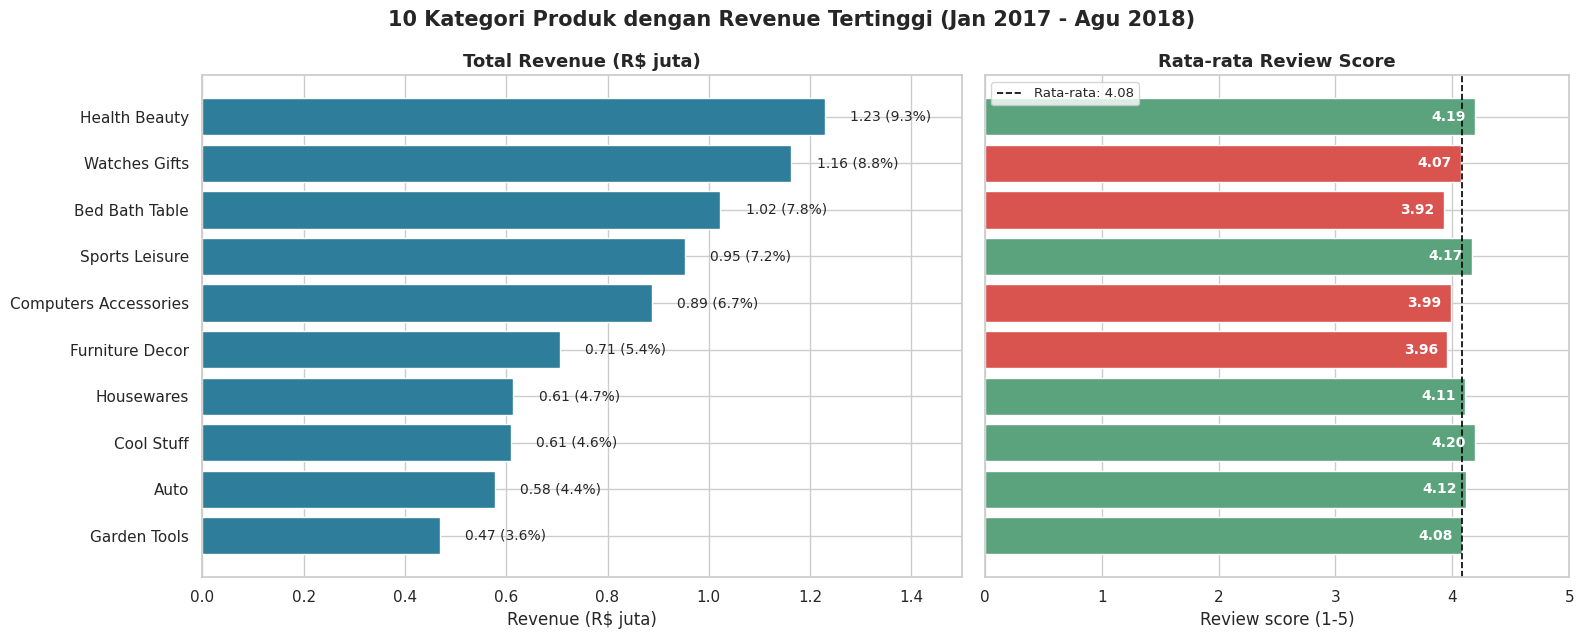

In [23]:
top10 = category_summary.head(10).iloc[::-1]   # dibalik agar peringkat 1 berada di paling atas
labels = top10.index.str.replace("_", " ").str.title()

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]}, sharey=True)

# (a) Total revenue
bars = axes[0].barh(labels, top10["total_revenue"] / 1e6, color="#2E7D9A")
axes[0].set_title("Total Revenue (R$ juta)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Revenue (R$ juta)")
for bar, share in zip(bars, top10["revenue_share_pct"]):
    axes[0].text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
                 f"{bar.get_width():.2f} ({share:.1f}%)", va="center", fontsize=10)
axes[0].set_xlim(0, top10["total_revenue"].max() / 1e6 * 1.22)

# (b) Rata-rata review score: garis putus = rata-rata seluruh item
overall = item_df["review_score"].mean()
colors = ["#D9534F" if v < overall else "#5BA37C" for v in top10["avg_review_score"]]  # merah = di bawah rata-rata
bars2 = axes[1].barh(labels, top10["avg_review_score"], color=colors)
axes[1].axvline(overall, color="black", linestyle="--", linewidth=1.2, label=f"Rata-rata: {overall:.2f}")
axes[1].legend(loc="upper left", frameon=True, facecolor="white", fontsize=9.5)
axes[1].set_title("Rata-rata Review Score", fontsize=13, fontweight="bold")
axes[1].set_xlabel(f"Review score (1-5)")
axes[1].set_xlim(0, 5)
for bar in bars2:
    axes[1].text(bar.get_width() - 0.08, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.2f}",
                 va="center", ha="right", fontsize=10, color="white", fontweight="bold")

fig.suptitle("10 Kategori Produk dengan Revenue Tertinggi (Jan 2017 - Agu 2018)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Revenue dipimpin `health_beauty`, `watches_gifts`, dan `bed_bath_table`.

Empat kategori besar (`watches gifts`, `bed_bath_table`, `computers_accessories`, `furniture_decor`) menyumbang revenue besar namun kepuasan pelanggannya paling rendah di antara 10 besar.

### Pertanyaan 2: Bagaimana tren pesanan dan revenue bulanan, serta kapan lonjakan tertinggi terjadi?

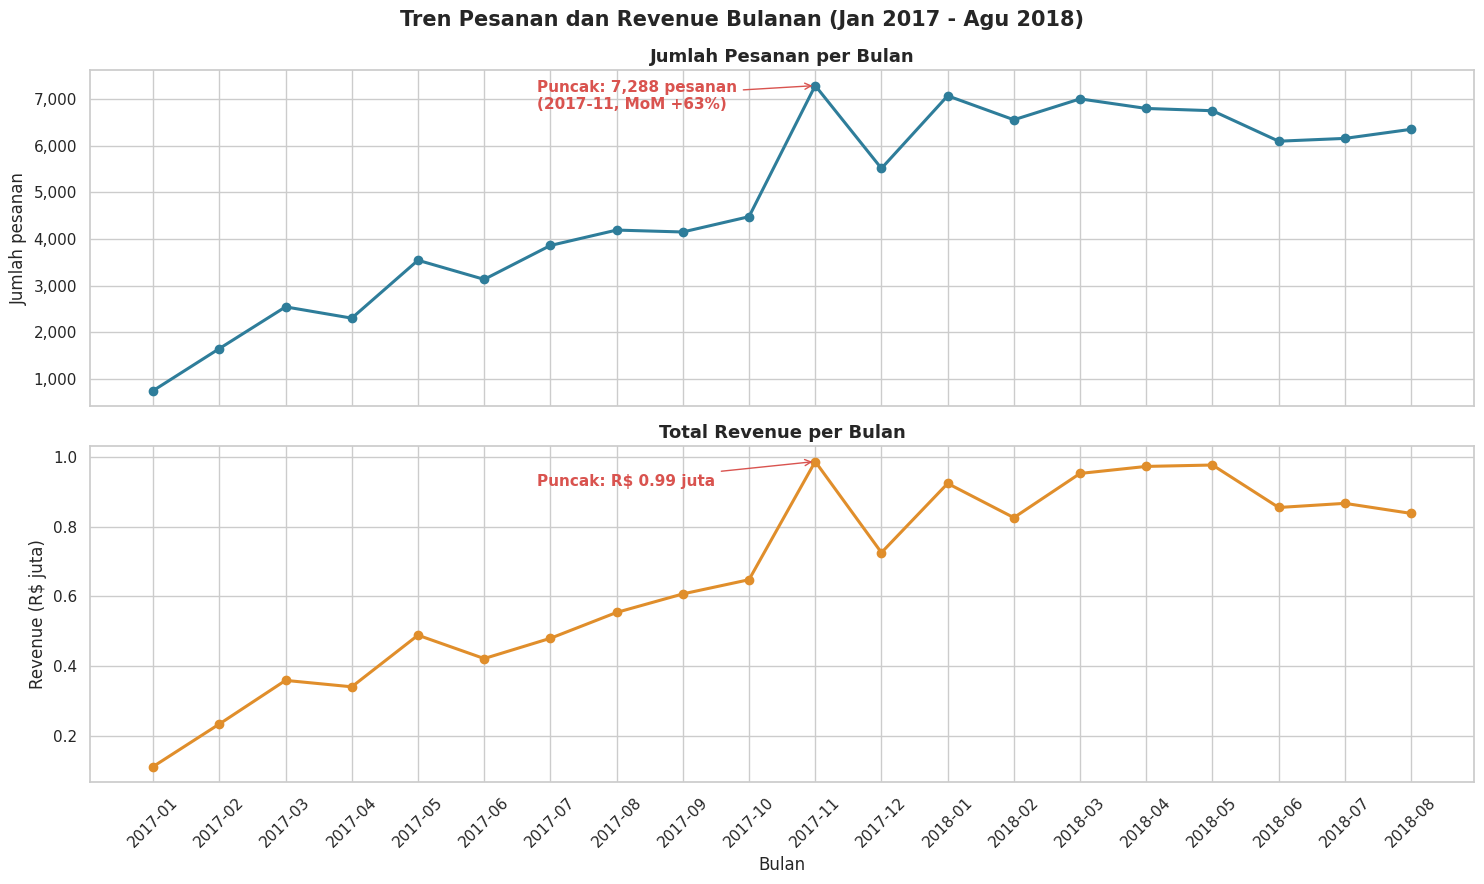

In [24]:
x_labels = monthly.index.astype(str)
peak = monthly["total_orders"].idxmax()
peak_pos = list(monthly.index).index(peak)

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

axes[0].plot(x_labels, monthly["total_orders"], marker="o", color="#2E7D9A", linewidth=2.2)
axes[0].set_title("Jumlah Pesanan per Bulan", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Jumlah pesanan")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].annotate(f"Puncak: {monthly.loc[peak, 'total_orders']:,} pesanan\n({peak}, MoM {monthly.loc[peak, 'orders_mom_pct']:+.0f}%)",
                 xy=(peak_pos, monthly.loc[peak, "total_orders"]),
                 xytext=(peak_pos - 4.2, monthly.loc[peak, "total_orders"] * 0.93),
                 arrowprops=dict(arrowstyle="->", color="#D9534F"), color="#D9534F", fontsize=11, fontweight="bold")

axes[1].plot(x_labels, monthly["total_revenue"] / 1e6, marker="o", color="#E08E2B", linewidth=2.2)
axes[1].set_title("Total Revenue per Bulan", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Revenue (R$ juta)")
axes[1].set_xlabel("Bulan")
axes[1].annotate(f"Puncak: R$ {monthly.loc[peak, 'total_revenue'] / 1e6:.2f} juta",
                 xy=(peak_pos, monthly.loc[peak, "total_revenue"] / 1e6),
                 xytext=(peak_pos - 4.2, monthly.loc[peak, "total_revenue"] / 1e6 * 0.93),
                 arrowprops=dict(arrowstyle="->", color="#D9534F"), color="#D9534F", fontsize=11, fontweight="bold")
plt.setp(axes[1].get_xticklabels(), rotation=45)

fig.suptitle("Tren Pesanan dan Revenue Bulanan (Jan 2017 - Agu 2018)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Pesanan dan revenue naik hampir terus-menerus sepanjang 2017 dan melonjak tajam pada **November 2017**, kemudian mendatar di kisaran 6.000-7.000 pesanan per bulan pada 2018. Bentuk kurva revenue hampir sama dengan kurva pesanan karena nilai rata-rata pesanan stabil. Data tidak memuat informasi kampanye, sehingga penyebab lonjakan November (kemungkinan terkait promosi musiman seperti Black Friday) tidak dapat dipastikan dari dataset ini.

### Pertanyaan 3: Seberapa besar dampak keterlambatan terhadap review score dan state mana yang paling sering terlambat?

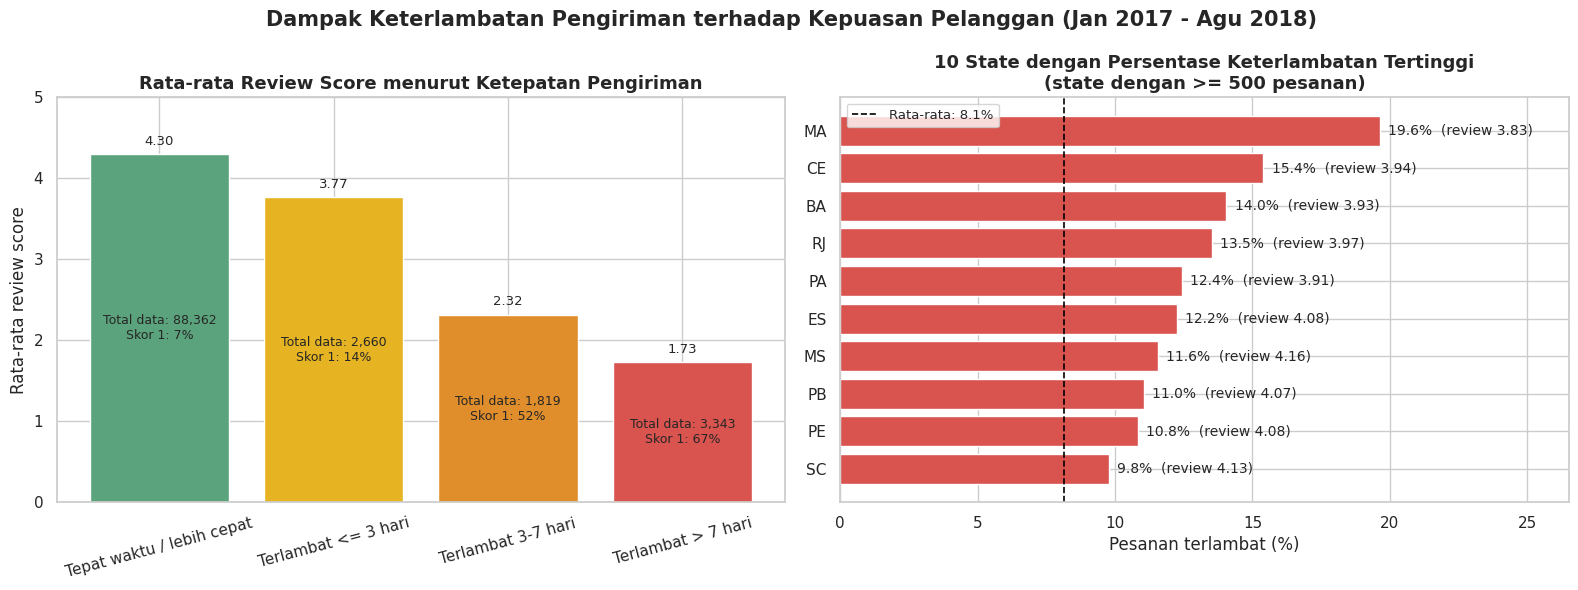

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# (a) Review score vs kelompok keterlambatan
colors = ["#5BA37C", "#E6B422", "#E08E2B", "#D9534F"]
bars = axes[0].bar(delay_review.index.astype(str), delay_review["avg_review_score"], color=colors)
axes[0].set_ylim(0, 5)
axes[0].set_title("Rata-rata Review Score menurut Ketepatan Pengiriman", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Rata-rata review score")
for bar, n, p1 in zip(bars, delay_review["total_orders"], delay_review["pct_review_1"]):
    x_center = bar.get_x() + bar.get_width() / 2
    height = bar.get_height()
    axes[0].text(x_center, height + 0.08, f"{height:.2f}", ha="center", va="bottom", fontsize=9.5)
    axes[0].text(x_center, height / 2, f"Total data: {n:,}\nSkor 1: {p1:.0f}%",ha="center", va="center", fontsize=9)
plt.setp(axes[0].get_xticklabels(), rotation=15)

# (b) 10 state dengan persentase keterlambatan tertinggi
top_late = state_major.head(10).iloc[::-1]
overall_late = order_df["is_late"].mean() * 100
bars2 = axes[1].barh(top_late.index, top_late["late_pct"], color="#D9534F")
axes[1].axvline(overall_late, color="black", linestyle="--", linewidth=1.2, label=f"Rata-rata: {overall_late:.1f}%")
axes[1].legend(loc="upper left", frameon=True, facecolor="white", fontsize=9.5)
axes[1].set_title("10 State dengan Persentase Keterlambatan Tertinggi\n(state dengan >= 500 pesanan)", fontsize=13, fontweight="bold")
axes[1].set_xlabel(f"Pesanan terlambat (%)")
for bar, rv in zip(bars2, top_late["avg_review_score"]):
    axes[1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                 f"{bar.get_width():.1f}%  (review {rv:.2f})", va="center", fontsize=10)
axes[1].set_xlim(0, top_late["late_pct"].max() * 1.35)

fig.suptitle("Dampak Keterlambatan Pengiriman terhadap Kepuasan Pelanggan (Jan 2017 - Agu 2018)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- Review score turun tajam begitu pesanan terlambat: Review score dari 4,30 jika tepat waktu menjadi 3,77 jika keterlambatan sampai 3 hari dan menjadi 2,32 jika lebih dari 3 hari. Pada keterlambatan lebih dari 7 hari, review skor menjadi 1.73.
- State di Utara/Timur Laut (MA, CE, BA, PA) memiliki keterlambatan tertinggi dan rata-rata review terendah. RJ juga di atas rata-rata (13,5%) dan karena volumenya besar (12.310 pesanan) maka RJ menyumbang 1.664 pesanan terlambat, terbanyak kedua setelah SP yang menyumbang keterlambatan sebanyak 2.384 pesanan.

## Analisis Lanjutan (Opsional)

### Analisis RFM (Recency, Frequency, Monetary)

Memahami perilaku pembelian ulang. Pelanggan dihitung berdasarkan `customer_unique_id`, dengan tanggal acuan sehari setelah transaksi terakhir. Segmentasi sederhana: *Repeat Customer* (>= 2 pesanan), *Recent High-Value* (recency & monetary skor 4-5), *Lapsed High-Value* (recency skor 1-2 dan monetary skor 4-5), dan sisanya *Other One-Time*.

Total pelanggan unik   : 93,080
Pelanggan repeat order : 2,786 (3.0%)



,customers,avg_recency_days,avg_frequency,avg_monetary,total_monetary,customer_share_pct,revenue_share_pct
segment,,,,,,,
Other One-Time,62112,236.93,1.00,77.22,"4,795,992.80",66.73,36.40
Recent High-Value,14438,91.41,1.00,267.14,"3,856,969.16",15.51,29.27
Lapsed High-Value,13744,391.66,1.00,276.43,"3,799,307.98",14.77,28.83
Repeat Customer,2786,219.34,2.11,259.99,"724,336.21",2.99,5.50


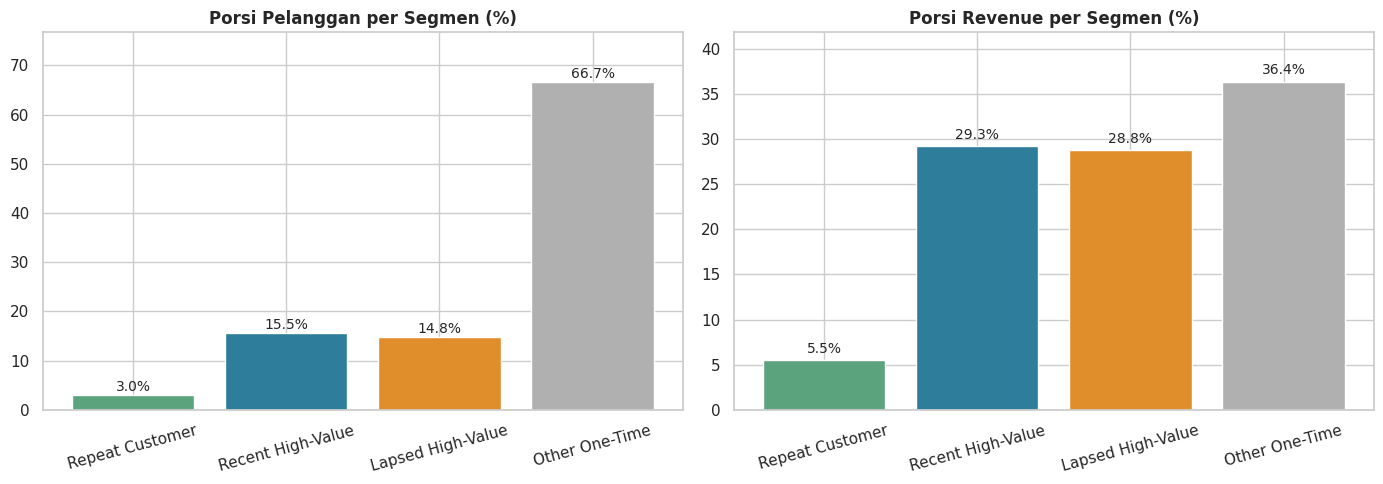

In [26]:
# Analisis RFM berdasarkan pelanggan unik (customer_unique_id)
snapshot_date = order_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = (order_df.groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"),
            monetary=("revenue", "sum"))
       .reset_index())
rfm["recency"] = (snapshot_date - rfm["last_purchase"]).dt.days

# Skor 1-5 (5 = terbaik). rank(method="first") dipakai karena banyak nilai yang sama
rfm["r_score"] = pd.qcut(rfm["recency"].rank(method="first", ascending=False), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(row):
    if row["frequency"] >= 2:
        return "Repeat Customer"
    if row["r_score"] >= 4 and row["m_score"] >= 4:
        return "Recent High-Value"
    if row["r_score"] <= 2 and row["m_score"] >= 4:
        return "Lapsed High-Value"
    return "Other One-Time"

rfm["segment"] = rfm.apply(segment, axis=1)

print(f"Total pelanggan unik   : {len(rfm):,}")
print(f"Pelanggan repeat order : {(rfm['frequency'] >= 2).sum():,} ({(rfm['frequency'] >= 2).mean():.1%})")
print()
seg_summary = (rfm.groupby("segment")
               .agg(customers=("customer_unique_id", "count"), avg_recency_days=("recency", "mean"),
                    avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"), total_monetary=("monetary", "sum"))
               .sort_values("customers", ascending=False))
seg_summary["customer_share_pct"] = seg_summary["customers"] / seg_summary["customers"].sum() * 100
seg_summary["revenue_share_pct"] = seg_summary["total_monetary"] / seg_summary["total_monetary"].sum() * 100
display(seg_summary)

order_seg = ["Repeat Customer", "Recent High-Value", "Lapsed High-Value", "Other One-Time"]
seg_plot = seg_summary.loc[order_seg]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = ["#5BA37C", "#2E7D9A", "#E08E2B", "#B0B0B0"]
axes[0].bar(order_seg, seg_plot["customer_share_pct"], color=palette)
axes[0].set_title("Porsi Pelanggan per Segmen (%)", fontsize=12, fontweight="bold")
axes[1].bar(order_seg, seg_plot["revenue_share_pct"], color=palette)
axes[1].set_title("Porsi Revenue per Segmen (%)", fontsize=12, fontweight="bold")
for ax, col in zip(axes, ["customer_share_pct", "revenue_share_pct"]):
    for i, v in enumerate(seg_plot[col]):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=10)
    ax.set_ylim(0, seg_plot[col].max() * 1.15)
    plt.setp(ax.get_xticklabels(), rotation=15)
plt.tight_layout()
plt.show()

**Insight:**
- Dari 93.080 pelanggan unik, hanya **2.786 (3,0%)** yang pernah membeli lebih dari sekali dan mereka menyumbang 5,5% revenue. Mayoritas pelanggan (97%) hanya bertransaksi satu kali.
- Segmen **Recent High-Value** (14.438 pelanggan) dan **Lapsed High-Value** (13.744 pelanggan) masing-masing menyumbang sekitar 29% revenue dengan belanja rata-rata 267 BRL - 276 BRL, sekitar 3,5 kali lipat *Other One-Time* (77 BRL). Segmen *Lapsed* terakhir belanja rata-rata 392 hari lalu, sehingga berisiko hilang.

### Analisis Geospasial
Peta interaktif berikut menampilkan seluruh state di atas peta dasar Brasil. **Ukuran lingkaran** menunjukkan jumlah pesanan (skala akar kuadrat agar SP tidak menutupi state kecil) dimana semakin besar lingkaran maka semakin tinggi jumlah pesanan, sedangkan **warna** menunjukkan persentase pesanan terlambat (kuning = rendah, merah tua = tinggi). Arahkan kursor atau klik lingkaran untuk melihat detail tiap state.

In [27]:
geo_valid = geolocation_df[
    geolocation_df["geolocation_lat"].between(-34, 6) &
    geolocation_df["geolocation_lng"].between(-74, -34)   # buang koordinat di luar wilayah Brasil
]
state_geo = (geo_valid.groupby("geolocation_state")
             .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean"))
             .reset_index().rename(columns={"geolocation_state": "customer_state"}))

# Gabungkan dengan ringkasan pengiriman per state (state_delivery dari tahap EDA)
geo_df = state_delivery.reset_index().merge(state_geo, on="customer_state", how="left")
geo_df["late_pct"] = geo_df["late_orders"] / geo_df["total_orders"] * 100
print("State tanpa koordinat:", geo_df["lat"].isna().sum())

colormap = cm.LinearColormap(
    colors=["#FFF3B0", "#FD8D3C", "#BD0026"],
    vmin=geo_df["late_pct"].min(),
    vmax=geo_df["late_pct"].max(),
    caption="Pesanan terlambat (%)",
)

# Pusat peta di tengah Brasil dengan tile Esri WorldGrayCanvas
m = folium.Map(
    location=[-14.2, -51.9],
    zoom_start=4,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri"
)

for _, row in geo_df.iterrows():
    detail = (f"<b>{row['customer_state']}</b><br>"
              f"Pesanan: {row['total_orders']:,}<br>"
              f"Terlambat: {row['late_pct']:.1f}%<br>"
              f"Rata-rata pengiriman: {row['avg_delivery_days']:.1f} hari<br>"
              f"Rata-rata review: {row['avg_review_score']:.2f}")
    folium.CircleMarker(
        location=[row["lat"], row["lng"]],
        radius=max(5, row["total_orders"] ** 0.5 / 6),
        color="black", weight=0.6,
        fill=True, fill_color=colormap(row["late_pct"]), fill_opacity=0.85,
        tooltip=f"{row['customer_state']}: {row['total_orders']:,} pesanan ({row['late_pct']:.1f}% terlambat)",
        popup=folium.Popup(detail, max_width=250),
    ).add_to(m)

colormap.add_to(m)

print("Catatan: Semakin besar lingkaran, semakin tinggi jumlah pesanan.")
display(m)
display(
    geo_df.sort_values("late_pct", ascending=False)[
        ["customer_state", "total_orders", "late_pct", "avg_delivery_days", "avg_review_score"]
    ].head(10)
)

State tanpa koordinat: 0
Catatan: Semakin besar lingkaran, semakin tinggi jumlah pesanan.


,customer_state,total_orders,late_pct,avg_delivery_days,avg_review_score
1,AL,396,23.99,24.52,3.85
9,MA,713,19.64,21.54,3.83
16,PI,475,16.00,19.44,3.99
5,CE,1273,15.40,21.24,3.94
24,SE,332,15.36,21.44,3.90
4,BA,3253,14.05,19.33,3.93
18,RJ,12310,13.52,15.30,3.97
26,TO,274,12.77,17.66,4.15
21,RR,40,12.50,29.91,3.90
13,PA,942,12.42,23.76,3.91


**Insight:**
- Pesanan sangat terpusat di **tenggara Brasil**: SP berukuran jauh paling besar (40.387 pesanan), diikuti RJ (12.310) dan MG (11.315). Wilayah Utara dan Tengah-Barat memiliki gelembung sangat kecil.
- Warna merah (keterlambatan tinggi) menumpuk di **Utara dan Timur Laut**: AL (24,0%), MA (19,6%), PI (16,0%), CE (15,4%), SE (15,4%), dan BA (14,0%). Wilayah ini berjarak jauh dari pusat pesanan di SP, yang hanya 5,9% terlambat.
- Peta menampilkan seluruh state, sehingga AL, PI, dan SE (yang berada di bawah ambang 500 pesanan pada grafik Pertanyaan 3) ikut terlihat. Namun volume pesanannya kecil (di bawah 500), jadi persentasenya lebih sensitif terhadap jumlah sampel.
- **RJ** unik: bergelembung besar sekaligus berwarna oranye-merah (13,5%). Sebagai pasar terbesar kedua, perbaikan logistik di RJ akan memberi dampak absolut terbesar setelah SP.
- Koordinat state adalah titik pusat rata-rata, bukan lokasi pelanggan sebenarnya, jadi peta ini menggambarkan pola antarwilayah, bukan jarak pengiriman yang tepat.

### Analisis Clustering

Pengelompokan pada analisis ini dilakukan dengan dua teknik:
- **Binning:** `pd.cut` membagi 27 state ke dalam 3 **zona logistik** berdasarkan persentase pesanan terlambat, dengan batas dari aturan bisnis: *Zona Aman* (<= rata-rata keseluruhan 8,1%), *Zona Waspada* (8,1% - 12%), dan *Zona Kritis* (> 12%). `pd.cut` juga dipakai untuk membagi state menurut volume pesanan (kecil < 500, menengah 500-3.000, besar > 3.000), serta pada kelompok keterlambatan di Pertanyaan 3 dan skor RFM (`pd.qcut`).
- **Manual Grouping:** pelanggan dikelompokkan ke dalam 4 segmen RFM (*Repeat Customer*, *Recent High-Value*, *Lapsed High-Value*, *Other One-Time*) berdasarkan aturan bisnis, dan state kritis dengan volume menengah/besar ditetapkan sebagai **state prioritas** perbaikan logistik.

Seluruh 27 state dimasukkan agar pengelompokan lengkap. State dengan sampel kecil (< 500 pesanan) tetap ditampilkan, tetapi persentasenya perlu dibaca hati-hati. Nilai rata-rata review dan lama pengiriman pada tabel zona adalah rata-rata antar-state (tidak dibobot jumlah pesanan).

,jumlah_state,total_pesanan,pesanan_terlambat,avg_review_score,avg_delivery_days,late_pct_zona,share_pesanan_pct
zona_logistik,,,,,,,
Zona Aman (<= rata-rata),10,65425,3875,4.19,17.30,5.92,68.02
Zona Waspada (rata-rata - 12%),6,8759,867,4.12,17.37,9.90,9.11
Zona Kritis (> 12%),11,22000,3080,3.95,20.90,14.00,22.87


Daftar state per zona:
- Zona Aman (<= rata-rata): RS (7.2%), DF (7.1%), MT (6.8%), SP (5.9%), MG (5.6%), PR (5.0%), AP (4.5%), AM (4.1%), AC (3.8%), RO (2.9%)
- Zona Waspada (rata-rata - 12%): MS (11.6%), PB (11.0%), RN (10.9%), PE (10.8%), SC (9.8%), GO (8.2%)
- Zona Kritis (> 12%): AL (24.0%), MA (19.6%), PI (16.0%), CE (15.4%), SE (15.4%), BA (14.0%), RJ (13.5%), TO (12.8%), RR (12.5%), PA (12.4%), ES (12.2%)


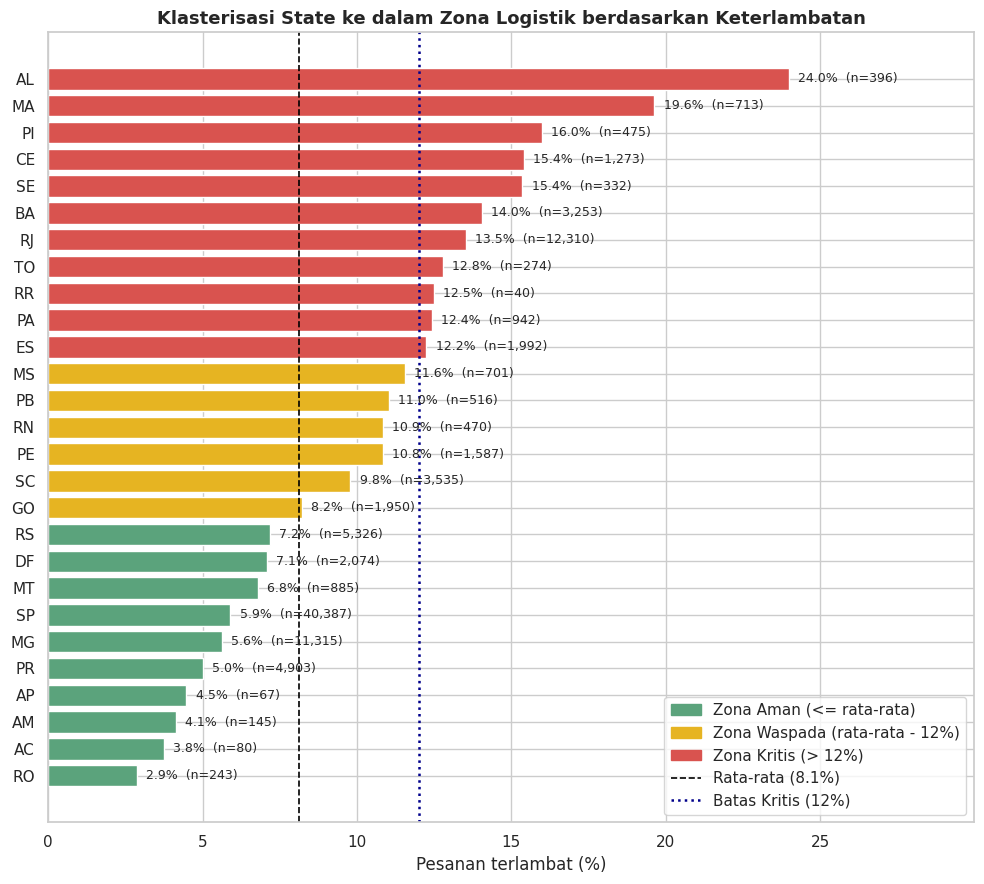

,customer_state,total_orders,late_pct,avg_review_score,kategori_volume
18,RJ,12310,13.52,3.97,Besar (>3.000)
4,BA,3253,14.05,3.93,Besar (>3.000)
7,ES,1992,12.25,4.08,Menengah (500-3.000)
5,CE,1273,15.40,3.94,Menengah (500-3.000)
13,PA,942,12.42,3.91,Menengah (500-3.000)
9,MA,713,19.64,3.83,Menengah (500-3.000)


In [28]:
# Clustering manual: mengelompokkan state ke dalam zona logistik berdasarkan persentase keterlambatan
overall_late = order_df["is_late"].mean() * 100

cluster_df = state_delivery.reset_index().copy()
cluster_df["late_pct"] = cluster_df["late_orders"] / cluster_df["total_orders"] * 100

# Binning: batas zona ditentukan dari aturan bisnis (rata-rata nasional dan 12%)
cluster_df["zona_logistik"] = pd.cut(
    cluster_df["late_pct"],
    bins=[0, overall_late, 12, 100],
    labels=["Zona Aman (<= rata-rata)", "Zona Waspada (rata-rata - 12%)", "Zona Kritis (> 12%)"],
)

# Manual grouping: tandai state bervolume besar dan state bersampel kecil
cluster_df["kategori_volume"] = pd.cut(cluster_df["total_orders"], bins=[0, 500, 3000, np.inf],
                                       labels=["Kecil (<500)", "Menengah (500-3.000)", "Besar (>3.000)"])

zone_summary = (cluster_df.groupby("zona_logistik", observed=True)
                .agg(jumlah_state=("customer_state", "count"),
                     total_pesanan=("total_orders", "sum"),
                     pesanan_terlambat=("late_orders", "sum"),
                     avg_review_score=("avg_review_score", "mean"),
                     avg_delivery_days=("avg_delivery_days", "mean")))
zone_summary["late_pct_zona"] = zone_summary["pesanan_terlambat"] / zone_summary["total_pesanan"] * 100
zone_summary["share_pesanan_pct"] = zone_summary["total_pesanan"] / zone_summary["total_pesanan"].sum() * 100
display(zone_summary)

print("Daftar state per zona:")
for zona, grp in cluster_df.sort_values("late_pct", ascending=False).groupby("zona_logistik", observed=True):
    daftar = ", ".join(f"{s} ({p:.1f}%)" for s, p in zip(grp["customer_state"], grp["late_pct"]))
    print(f"- {zona}: {daftar}")

# Visualisasi: seluruh state, diwarnai menurut zona
palette = {
    "Zona Aman (<= rata-rata)": "#5BA37C",
    "Zona Waspada (rata-rata - 12%)": "#E6B422",
    "Zona Kritis (> 12%)": "#D9534F"
}
plot_df = cluster_df.sort_values("late_pct")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(plot_df["customer_state"], plot_df["late_pct"], color=plot_df["zona_logistik"].astype(str).map(palette))
line1 = ax.axvline(overall_late, color="black", linestyle="--", linewidth=1.2)
line2 = ax.axvline(12, color="darkblue", linestyle=":", linewidth=1.8)
for i, (p, n) in enumerate(zip(plot_df["late_pct"], plot_df["total_orders"])):
    ax.text(p + 0.3, i, f"{p:.1f}%  (n={n:,})", va="center", fontsize=9)
ax.set_xlim(0, plot_df["late_pct"].max() * 1.25)
ax.set_xlabel("Pesanan terlambat (%)")
ax.set_title("Klasterisasi State ke dalam Zona Logistik berdasarkan Keterlambatan", fontsize=13, fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()] + [line1, line2]
labels = list(palette.keys()) + [f"Rata-rata ({overall_late:.1f}%)", "Batas Kritis (12%)"]
ax.legend(handles, labels, loc="lower right", frameon=True, facecolor="white")
plt.tight_layout()
plt.show()

# State prioritas: zona kritis dengan volume menengah/besar (dampak ke pelanggan paling besar)
cluster_df[(cluster_df["zona_logistik"] == "Zona Kritis (> 12%)") & (cluster_df["total_orders"] >= 500)] \
    .sort_values("total_orders", ascending=False)[["customer_state", "total_orders", "late_pct", "avg_review_score", "kategori_volume"]]

**Insight:**
- **Zona Aman** (10 state, termasuk SP, MG, PR, RS) menampung **68%** pesanan dengan keterlambatan hanya 5,9% dan review rata-rata 4,19. **Zona Kritis** (11 state) menampung **22,9%** pesanan dengan keterlambatan **14,0%**, review rata-rata 3,95, dan lama pengiriman rata-rata 20,9 hari (dibanding 17,3 hari di Zona Aman).
- Zona Kritis terdiri dari AL, MA, PI, CE, SE, BA, RJ, TO, RR, PA, dan ES. Sebagian besar berada di Utara dan Timur Laut, dengan dua pengecualian di Tenggara: **RJ** dan **ES**.
- **State prioritas** (Zona Kritis dengan >= 500 pesanan) adalah **RJ** (12.310 pesanan), **BA** (3.253), **ES** (1.992), **CE** (1.273), **PA** (942), dan **MA** (713). RJ dan BA berada di kategori volume besar, sehingga perbaikan di sana berdampak paling luas.
- AL (24,0%), SE, PI, TO, dan RR juga masuk Zona Kritis, tetapi bervolume kecil (< 500 pesanan, RR hanya 40), sehingga persentasenya mudah berubah dan lebih tepat dipantau dulu sebelum diambil tindakan besar.
- Review rata-rata turun searah dengan zona (4,19 → 4,12 → 3,95), sejalan dengan temuan Pertanyaan 3 bahwa keterlambatan menekan kepuasan pelanggan. Ini tetap korelasi, bukan bukti sebab-akibat.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pendapatan terkonsentrasi pada 10 kategori yang menyumbang **62,5%** dari total 13,18 juta BRL, dipimpin `health_beauty` ( 1,23 juta BRL), `watches_gifts` (1,16 juta BRL), dan `bed_bath_table` (1,02 juta BRL). `health_beauty` dan `sports_leisure` bernilai tinggi sekaligus berkepuasan baik (review 4,19 dan 4,17). `watches_gifts` juga berpendapatan besar dengan review 4,07, hanya 0,01 di bawah rata-rata (4,08), sehingga praktis setara rata-rata. Sebaliknya `bed_bath_table` (3,92), `computers_accessories` (3,99), dan `furniture_decor` (3,96) berpendapatan besar tetapi berkepuasan jelas di bawah rata-rata.
- **Conclusion pertanyaan 2:** Bisnis tumbuh pesat: Jan-Agu 2018 naik **+140% pesanan dan +141% revenue** dibanding Jan-Agu 2017. Lonjakan tertinggi terjadi pada **November 2017** (7.288 pesanan, +62,8% MoM, 987.648 BRL), diikuti penurunan 24,4% di Desember. Sepanjang 2018 pertumbuhan mendatar di 6.000-7.000 pesanan per bulan dengan nilai rata-rata pesanan yang stabil (126 BRL - 149 BRL).
- **Conclusion pertanyaan 3:** Keterlambatan menurunkan kepuasan secara drastis: review rata-rata **2,57** untuk pesanan terlambat vs **4,30** untuk tepat waktu (selisih 1,73 poin), dan hanya 1,73 bila terlambat lebih dari 7 hari. Secara keseluruhan 8,1% pesanan terlambat, tetapi di **MA (19,6%), CE (15,4%), BA (14,0%), RJ (13,5%), dan PA (12,4%)** angkanya jauh lebih tinggi dibanding SP (5,9%).
- **Temuan tambahan (RFM):** 97% pelanggan hanya membeli sekali, terdapat ±28 ribu pelanggan bernilai tinggi (belanja rata-rata 267 BRL - 276 BRL) yang belum melakukan pembelian ulang.
- **Temuan tambahan (Geospasial):** Pesanan terkonsentrasi di SP, RJ, dan MG, sedangkan keterlambatan tertinggi berada di Utara dan Timur Laut (AL, MA, PI, CE, SE, BA), yaitu wilayah yang jauh dari pusat pesanan. Hal ini mendukung rekomendasi untuk fokus memperbaiki logistik di wilayah tersebut, serta mempertimbangkan penambahan titik distribusi/gudang di Timur Laut.
- **Temuan tambahan (Clustering):** Dari 27 state, 11 masuk **Zona Kritis** (keterlambatan > 12%), yang menampung 22,9% pesanan dengan review rata-rata 3,95. State prioritas dengan volume cukup besar adalah RJ, BA, ES, CE, PA, dan MA.

**Rekomendasi Action Item:**
- **Prioritaskan anggaran promosi** pada `health_beauty` dan `sports_leisure` karena revenue besar dan review baik, `watches_gifts` juga memiliki revenue besar dengan review score yang hanya berbeda 0,01 dari rata-rata. Lakukan **audit kualitas** (seller, deskripsi produk, kemasan, retur) pada `bed_bath_table`, `computers_accessories`, serta `furniture_decor` agar kategori berpendapatan besar tidak menekan kepuasan.
- **Siapkan periode puncak sejak Oktober:** tambah stok, kapasitas seller dan kurir menjelang November (lonjakan +63% MoM pada 2017), serta rancang kampanye lain (mis. promo tengah tahun) untuk mengangkat pesanan yang mendatar di 2018.
- **Tekan keterlambatan di wilayah prioritas:**
- - (1) tinjau ulang estimasi pengiriman dan SLA kurir untuk MA, CE, BA, dan PA
- - (2) fokus RJ karena volumenya besar
- - (3) kirim notifikasi proaktif dan kompensasi (voucher/ongkir gratis) untuk pesanan yang terlambat > 3 hari karena di titik inilah review turun di bawah 2,5. Pantau KPI persentase pesanan terlambat per state tiap bulan dengan target awal menurunkan rata-rata dari 8,1%.
- **Dorong pembelian ulang:** kirim penawaran *win-back* (voucher, email/WA) ke segmen *Lapsed High-Value* dan program *cross-sell* pasca-pembelian kepada *Recent High-Value* agar proporsi pelanggan repeat naik dari 3%.
- **Catatan keterbatasan:** analisis memakai pesanan `delivered` dengan revenue dari `price` (tanpa ongkir), hubungan keterlambatan-review bersifat korelasi, dan penyebab lonjakan November tidak dapat dipastikan karena data kampanye tidak tersedia.